   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 40.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.7 MB/s eta 0:00:00
Mounted at /content/drive
Using device: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


open_clip_model.safetensors:   0%|          | 0.00/3.53G [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/34.4M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/327 [00:00<?, ?B/s]

Classi: 25
Esempio classi: ['Achaemenid', 'American Foursquare', 'American craftsman style', 'Ancient Egyptian', 'Art Deco', 'Art Nouveau', 'Baroque', 'Bauhaus', 'Beaux-Arts', 'Byzantine']
temp=0.50 -> top1=0.7164  macroF1=0.7128  top5=0.9607  balAcc=0.7116
temp=1.00 -> top1=0.7164  macroF1=0.7128  top5=0.9607  balAcc=0.7116
temp=2.00 -> top1=0.7164  macroF1=0.7128  top5=0.9607  balAcc=0.7116

Best temperature: 0.5
FINAL -> Top-1=0.7164 | Macro-F1=0.7128 | Top-5=0.9607 | BalAcc=0.7116
Latency: 104.4 ms/img | GPU-h: 0.00
                          precision    recall  f1-score   support

              Achaemenid     0.8429    1.0000    0.9147        59
     American Foursquare     0.6282    0.8909    0.7368        55
American craftsman style     0.8605    0.6607    0.7475        56
        Ancient Egyptian     0.9688    0.9118    0.9394        68
                Art Deco     0.7674    0.5156    0.6168        64
             Art Nouveau     0.9149    0.7288    0.8113        59
           

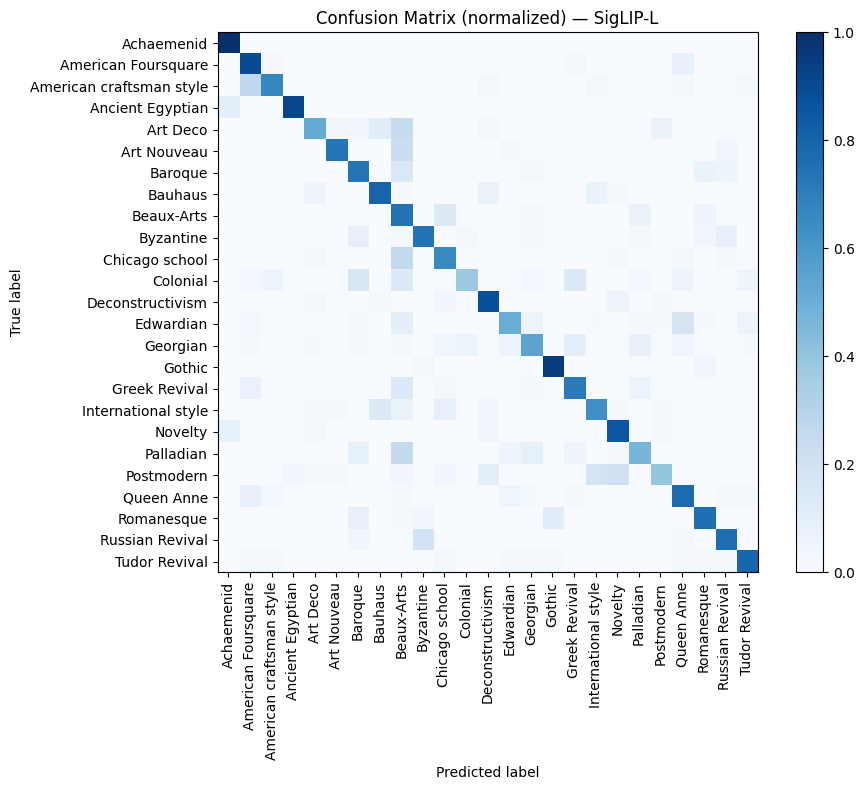

In [1]:
# === Install ===
!pip -q install open_clip_torch scikit-learn matplotlib pandas tqdm
!pip -q install --upgrade "open_clip_torch>=2.24.0" "timm>=0.9.16"


# === Imports & Config ===
import os, time, json, math
from datetime import datetime
import numpy as np
import pandas as pd
import torch
from tqdm import tqdm
import open_clip
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score, classification_report, top_k_accuracy_score,
    f1_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# monto Drive per Colab
from google.colab import drive
drive.mount('/content/drive', force_remount=True)



# --------- CONFIG MODELLO    (MODIFICA QUI) ---------
DATA_ROOT = "/content/drive/MyDrive/ArchiStyles-2"  # cartella dataset
SPLIT = "valid"                                                                 # "test" | "valid" | "train"
BATCH_SIZE = 32                                                                 # SigLIP-L è pesante: 32 è un punto di partenza

# Modello SigLIP-L
MODEL_NAME = "ViT-L-16-SigLIP2-384"
PRETRAINED = "webli"

# Prompt templates
TEMPLATES = [
    # formule base (foto/immagine/quadro) + "architecture"
    "a photo of {} architecture",
    "a photograph of {} architecture",
    "an image of {} architecture",
    "a picture of {} architecture",

    # “architectural style” (esplicita il concetto di stile)
    "a photo of the {} architectural style",
    "the {} architectural style",

    # “style” generico (utile quando la classe contiene già 'style')
    "a photo of a {} style building",
    "a {} style building",
    "a building in the {} style",

    # varianti molto efficaci per gli edifici
    "{}-style building",
    "a {} building",
    "a building of {} architecture",
    "a representation of {} architecture",

    # dettaglio tipico per architettura
    "the facade of a {} building",
    "an example of {} architecture",
]


# Effort & note per la scorecard
EFFORT_HOURS = 0.5   # stima ore uomo per questa run
NOTES = "SigLIP-L zero-shot with deeep prompt ensemble + temperature grid"
# -----------------------------------------

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)


# === Model & Dataset ===
# Modello + preprocess

model, preprocess_train, preprocess_val = open_clip.create_model_and_transforms(
    model_name=MODEL_NAME,
    pretrained=PRETRAINED
)
# usa il preprocess di valid per l'inferenza
preprocess = preprocess_val

tokenizer = open_clip.get_tokenizer(MODEL_NAME)

model.to(device).eval()

# Dataset + DataLoader
assert os.path.isdir(DATA_ROOT), f"DATA_ROOT non trovato: {DATA_ROOT}"
split_path = os.path.join(DATA_ROOT, SPLIT)
assert os.path.isdir(split_path), f"Split '{SPLIT}' non trovato in {DATA_ROOT}"
ds = ImageFolder(split_path, transform=preprocess)
dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
classnames = ds.classes
num_classes = len(classnames)

print("Classi:", num_classes)
print("Esempio classi:", classnames[:10])

# === Prompt generation & text features ===
'''
def make_prompts(cname):
    return [t.format(cname) for t in TEMPLATES] + [f"{cname} architecture"]     #t.format() serve per sostituire il segnaposto dells tringa n-esima t presa da TEMPLATES
'''
def make_prompts(cname):
    return [t.format(cname) for t in TEMPLATES]

# Tokenize prompts (prompt ensemble)
all_prompts, class_offsets = [], [0]
for cname in classnames:                                                        #per ogni nome nella lista delle classi (ovvero ds.classes ovvero i nomi delle cartelle del dataset)
    ps = make_prompts(cname)
    all_prompts.extend(ps)
    class_offsets.append(len(all_prompts))

tokens = tokenizer(all_prompts).to(device)

with torch.no_grad():
    text_features = model.encode_text(tokens)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)

# Grid semplice per temperature (moltiplica i logits)
TEMP_GRID = [0.5, 1.0, 2.0]

# === Inference helpers ===
def evaluate_with_temp(temp):
    y_true, y_pred = [], []
    probs_collector = []
    model_dtype = next(model.parameters()).dtype

    with torch.no_grad():
        for imgs, labels in dl:
            imgs = imgs.to(device, dtype=model_dtype)
            img_features = model.encode_image(imgs)
            img_features = img_features / img_features.norm(dim=-1, keepdim=True)

            # logit scale nativo * temperature
            logit_scale = model.logit_scale.exp() * temp
            logits = logit_scale * (img_features @ text_features.T)

            # aggrega prompt per classe
            class_logits = []
            for i in range(num_classes):
                s, e = class_offsets[i], class_offsets[i+1]
                class_logits.append(logits[:, s:e].mean(dim=1))
            class_logits = torch.stack(class_logits, dim=1)

            prob = class_logits.softmax(dim=-1)
            pred = prob.argmax(dim=-1)

            y_true.extend(labels.tolist())
            y_pred.extend(pred.tolist())
            probs_collector.append(prob.cpu().numpy())

    y_true = np.array(y_true, dtype=int)
    y_pred = np.array(y_pred, dtype=int)
    probs = np.concatenate(probs_collector, axis=0)

    top1 = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    top5 = top_k_accuracy_score(y_true, probs, k=min(5, num_classes), labels=np.arange(num_classes))
    bal_acc = balanced_accuracy_score(y_true, y_pred)

    return top1, macro_f1, top5, bal_acc, y_true, y_pred, probs




# === Temperature search (nota: per rigore andrebbe su VALID) ===
best = None
for t in TEMP_GRID:
    top1, macro_f1, top5, bal_acc, _, _, _ = evaluate_with_temp(t)
    print(f"temp={t:.2f} -> top1={top1:.4f}  macroF1={macro_f1:.4f}  top5={top5:.4f}  balAcc={bal_acc:.4f}")
    if best is None or top1 > best[0]:
        best = (top1, macro_f1, top5, bal_acc, t)

best_top1, best_macro_f1, best_top5, best_bal_acc, best_temp = best
print("\nBest temperature:", best_temp)

# === Final evaluation + latency + report & confusion matrix ===
top1, macro_f1, top5, bal_acc, y_true, y_pred, probs = evaluate_with_temp(best_temp)

# Latency (ms/img)
def measure_latency(num_batches=20):
    model_dtype = next(model.parameters()).dtype
    # warmup
    it = iter(dl)
    for _ in range(3):
        try:
            imgs, _ = next(it)
        except StopIteration:
            it = iter(dl)
            imgs, _ = next(it)
        imgs = imgs.to(device, dtype=model_dtype)
        with torch.no_grad():
            _ = model.encode_image(imgs)
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    # timed
    times = []
    it = iter(dl)
    for _ in range(num_batches):
        try:
            imgs, _ = next(it)
        except StopIteration:
            it = iter(dl)
            imgs, _ = next(it)
        imgs = imgs.to(device, dtype=model_dtype)
        t0 = time.time()
        with torch.no_grad():
            _ = model.encode_image(imgs)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        dt = time.time() - t0
        ms_per_img = (dt / imgs.size(0)) * 1000.0
        times.append(ms_per_img)
    return float(np.mean(times))

latency_ms = measure_latency(num_batches=min(20, math.ceil(len(ds)/BATCH_SIZE)))
gpu_hours = 0.0  # zero-shot

print(f"FINAL -> Top-1={top1:.4f} | Macro-F1={macro_f1:.4f} | Top-5={top5:.4f} | BalAcc={bal_acc:.4f}")
print(f"Latency: {latency_ms:.1f} ms/img | GPU-h: {gpu_hours:.2f}")



# === Classification report & confusion matrix ===
print(classification_report(y_true, y_pred, target_names=classnames, digits=4, zero_division=0))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    display_labels=classnames,
    normalize="true",
    cmap="Blues",
    include_values=False,
    xticks_rotation=90,
    ax=ax
)
ax.set_title("Confusion Matrix (normalized) — SigLIP-L")
plt.tight_layout()
plt.show()
